In [1]:
import pandas as pd
import numpy as np
import joblib
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
happiness_df = pd.read_csv("../../data/processed/world_happiness_2015_2019_clean.csv")


## Avoid target leakage


### Multiple Linear Regression Equation

Multiple Linear Regression is represented by the following equation:

$$
Y = X\beta + \epsilon
$$

Where:

- **\(Y\)**: Response vector, representing the happiness score we want to predict.
- **\(X\)**: Feature matrix containing the 6 predictor variables used by the model.
- **\(\beta\)**: Vector of coefficients or weights learned by the model during training.
- **\(\epsilon\)**: Error term, representing the variability in the response that the model cannot explain.



In [3]:
features = [
    'gdp_per_capita', 'social_support', 'healthy_life_expectancy', 
    'freedom', 'generosity', 'perceptions_of_corruption'
]
target = 'happiness_score'

X = happiness_df[features]
y = happiness_df[target]

### We partition the data into training and test sets using a fixed random seed for reproducibility.


### Expanding Window Validation - Results Interpretation

The table illustrates the progressive expansion of the training dataset across four temporal validation iterations.

In each iteration, the Decision Tree model is trained using historical observations and evaluated on the following year.

As the iterations progress, additional historical records are incorporated into the training dataset:

- Iteration 1: 158 training samples (2015), validated on 157 samples (2016).
- Iteration 2: 315 training samples (2015–2016), validated on 155 samples (2017).
- Iteration 3: 470 training samples (2015–2017), validated on 156 samples (2018).
- Iteration 4: 626 training samples (2015–2018), validated on 156 samples (2019).

This approach preserves chronological order and prevents future observations from being used during previous training iterations.

The main objective is to evaluate how the model performs when predicting future Happiness Scores using progressively larger historical datasets.


In [4]:
validation_years = [2016, 2017, 2018, 2019]

splits = []
split_summary = []

for iteration, val_year in enumerate(validation_years, start=1):

    train_df = happiness_df[
        happiness_df['year'] < val_year
    ].copy()

    test_df = happiness_df[
        happiness_df['year'] == val_year
    ].copy()

    splits.append((train_df, test_df))

    split_summary.append({
        'Iteration': iteration,
        'Training Years': f'2015-{val_year - 1}',
        'Validation Year': val_year,
        'Train': len(train_df),
        'Test': len(test_df)
    })

split_summary_df = pd.DataFrame(split_summary)

display(split_summary_df)


,Iteration,Training Years,Validation Year,Train,Test
0,1,2015-2015,2016,158,157
1,2,2015-2016,2017,315,155
2,3,2015-2017,2018,470,156
3,4,2015-2018,2019,626,156


### 2.1. Random Forest Model Training and Prediction

The Random Forest model is trained and evaluated using an Expanding Window temporal validation strategy.

Random Forest is an ensemble learning algorithm that combines the predictions of multiple decision trees to produce a final prediction. In a regression problem, the final prediction is calculated as the average of the predictions generated by all trees.

**Random Forest prediction formula:**

$$
\hat{y}(X) = \frac{1}{B}\sum_{b=1}^{B} T_b(X)
$$

Where:

- $\hat{y}(X)$: final predicted Happiness Score.
- $B$: total number of decision trees in the forest (100).
- $T_b(X)$: prediction generated by the $b$-th decision tree for input features $X$.
- $X$: six predictor variables used by the model.

**Model configuration:**

- `n_estimators=100`: the model uses 100 decision trees. Their predictions are averaged to obtain the final result.
- `random_state=42`: ensures reproducibility.
- `n_jobs=-1`: uses all available CPU cores for parallel processing.

**Training process:**

The process is repeated across four iterations. In each iteration, a new Random Forest model is trained using historical data and evaluated on the following year.

For each iteration, the dataset is divided into training and validation sets:

- $X_{\text{train}}$: six predictor variables from previous years.
- $y_{\text{train}}$: actual Happiness Score values from previous years.
- $X_{\text{val}}$: predictor variables from the validation year.
- $y_{\text{val}}$: actual Happiness Score values used for evaluation.

The model learns from the training data:

$$
M_k = \operatorname{RandomForest}(X_{\text{train}}, y_{\text{train}})
$$

Then, predictions are generated for the validation dataset:

$$
\hat{y}_{\text{val}} = M_k(X_{\text{val}})
$$

For each observation, the Random Forest model calculates the predictions of its 100 decision trees and averages them to produce the final predicted Happiness Score.

Where:

- $M_k$: Random Forest model trained during iteration $k$.
- $X_{\text{val}}$: validation features.
- $\hat{y}_{\text{val}}$: predicted Happiness Score.

**Results storage:**

For each iteration, the process stores:

- Iteration number.
- Validation year.
- Actual values ($y_{\text{true}}$).
- Predicted values ($y_{\text{pred}}$).
- Number of training records.
- Number of validation records.

These stored predictions are subsequently used to calculate the evaluation metrics: MAE, RMSE, and R².

**Purpose:** This approach evaluates the model's ability to predict future Happiness Scores using historical information, while preserving the chronological order of the dataset.

In [5]:

models = []
predictions = []

print("Training Random Forest with temporal validation...\n")

for iteration, (train_df, val_df) in enumerate(splits, start=1):

    X_train = train_df[features]
    y_train = train_df[target]

    X_val = val_df[features]
    y_val = val_df[target]

    model = RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train, y_train)

    y_pred = model.predict(X_val)

    models.append(model)
    predictions.append({
        "iteration": iteration,
        "year": val_df['year'].iloc[0],
        "y_true": y_val,
        "y_pred": y_pred,
        "training_records": len(train_df),
        "validation_records": len(val_df)
    })


Training Random Forest with temporal validation...



### 2.2. Model Evaluation Metrics

The Random Forest model is evaluated using three regression metrics: Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and the Coefficient of Determination (R²).

These metrics are calculated independently for each validation iteration using the actual values ($y_{\text{true}}$) and predicted values ($y_{\text{pred}}$).

**1. Mean Absolute Error (MAE)**

MAE measures the average absolute difference between the actual and predicted values. It indicates how far the model's predictions are from the actual Happiness Scores, without considering the direction of the error.

Formula:

$$
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i-\hat{y}_i|
$$

Where:

- $n$: number of observations in the validation dataset.
- $y_i$: actual Happiness Score for observation $i$.
- $\hat{y}_i$: predicted Happiness Score for observation $i$.

**Interpretation:** Lower MAE values indicate more accurate predictions. The metric is expressed in the same units as the Happiness Score.

**2. Root Mean Squared Error (RMSE)**

RMSE measures the square root of the average squared differences between actual and predicted values. Unlike MAE, it penalizes larger prediction errors more heavily because the errors are squared before averaging.

Formula:

$$
RMSE = \sqrt{\frac{1}{n}\sum_{i=1}^{n}(y_i-\hat{y}_i)^2}
$$

Where:

- $n$: number of observations in the validation dataset.
- $y_i$: actual Happiness Score for observation $i$.
- $\hat{y}_i$: predicted Happiness Score for observation $i$.

**Interpretation:** Lower RMSE values indicate better predictive performance. A considerably higher RMSE compared to MAE may indicate the presence of some large prediction errors.

**3. Coefficient of Determination (R²)**

R² measures how well the model explains the variability of the actual Happiness Scores compared to a baseline that predicts the mean of the observed values.

Formula:

$$
R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i-\hat{y}_i)^2}{\sum_{i=1}^{n}(y_i-\bar{y})^2}
$$

Where:

- $n$: number of observations in the validation dataset.
- $y_i$: actual Happiness Score for observation $i$.
- $\hat{y}_i$: predicted Happiness Score for observation $i$.
- $\bar{y}$: mean of the actual Happiness Scores in the validation dataset.

**Interpretation:**

- $R^2 = 1$: perfect predictions.
- $R^2 = 0$: the model performs equivalently to predicting the mean of the actual validation values.
- $R^2 < 0$: the model performs worse than the mean-based baseline.

Unlike MAE and RMSE, higher R² values indicate better predictive performance.

**Evaluation implementation:**

The metrics are calculated for each validation iteration using the following Python functions:

```python
mae = mean_absolute_error(y_val, y_pred)

rmse = np.sqrt(mean_squared_error(y_val, y_pred))

r2 = r2_score(y_val, y_pred)
```

The resulting metrics are stored alongside the iteration number, validation year, and training and validation record counts.

**Purpose:** Using these three metrics provides a more complete evaluation of the Random Forest model. MAE measures average absolute prediction errors, RMSE highlights larger errors, and R² evaluates how well the model explains the variability in Happiness Scores.

In [6]:

results = []

for prediction in predictions:

    y_val = prediction["y_true"]
    y_pred = prediction["y_pred"]

    mae = mean_absolute_error(y_val, y_pred)
    rmse = np.sqrt(mean_squared_error(y_val, y_pred))
    r2 = r2_score(y_val, y_pred)

    results.append({
        "Iteration": prediction["iteration"],
        "Validation Year": prediction["year"],
        "Training Records": prediction["training_records"],
        "Validation Records": prediction["validation_records"],
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })


In [7]:

results_df = pd.DataFrame(results)

print("=== Random Forest Validation Results ===")

display(results_df.round(4))

print(f"Average R2: {results_df['R2'].mean():.4f}")


=== Random Forest Validation Results ===


,Iteration,Validation Year,Training Records,Validation Records,MAE,RMSE,R2
0,1,2016,158,157,0.4668,0.5890,0.7321
1,2,2017,315,155,0.3909,0.4885,0.8123
2,3,2018,470,156,0.3624,0.4586,0.8311
3,4,2019,626,156,0.4824,0.6167,0.6911


Average R2: 0.7667


In [8]:
import joblib
import os
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor

print("Exporting final model and metrics...\n")

# 1. Create and train the final Pipeline (all data: 2015-2019)
final_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1))
])
final_pipeline.fit(X, y)

# 2. Save the serialized model (model.pkl)
model_path = '../../models/model.pkl'
joblib.dump(final_pipeline, model_path)
print(f"✅ Model successfully exported to: {model_path}")

# 3. Export the evaluation metrics to CSV
csv_path = '../../data/processed/random_forest_metrics.csv'

# Create the directory if it doesn't exist to avoid errors
os.makedirs(os.path.dirname(csv_path), exist_ok=True)

# Save the DataFrame (results_df) to CSV
results_df.to_csv(csv_path, index=False)
print(f"✅ Metrics successfully exported to: {csv_path}")

Exporting final model and metrics...

✅ Model successfully exported to: ../../models/model.pkl
✅ Metrics successfully exported to: ../../data/processed/random_forest_metrics.csv


In [9]:

df_res = pd.DataFrame(results)

In [10]:

# 2. Extraer los datos para el gráfico
años = df_res['Validation Year']
rmse_scores = df_res['RMSE']
r2_scores = df_res['R2']

# 3. Crear la gráfica
plt.figure(figsize=(10, 5))

# Líneas (Azul para RMSE, Verde para R²)
plt.plot(años, rmse_scores, marker='o', color='#3B82F6', linewidth=2.5, markersize=8, label='RMSE (Error)')
plt.plot(años, r2_scores, marker='s', color='#10B981', linewidth=2.5, markersize=8, label='R² (Precisión)')

# 4. Poner los números encima de cada punto
for i, txt in enumerate(rmse_scores):
    plt.text(años.iloc[i], txt + 0.015, f"{txt:.3f}", ha='center', color='#3B82F6', fontweight='bold')
for i, txt in enumerate(r2_scores):
    plt.text(años.iloc[i], txt + 0.015, f"{txt:.3f}", ha='center', color='#10B981', fontweight='bold')

# 5. Detalles estéticos
plt.title('Rendimiento del modelo Random Forest por Año', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Año de validación', fontsize=12)
plt.xticks(años) # Forzar a que salgan solo los años exactos
plt.grid(True, alpha=0.3)
plt.legend(loc='center right', fontsize=11)

plt.tight_layout()
plt.show()

NameError: name 'plt' is not defined

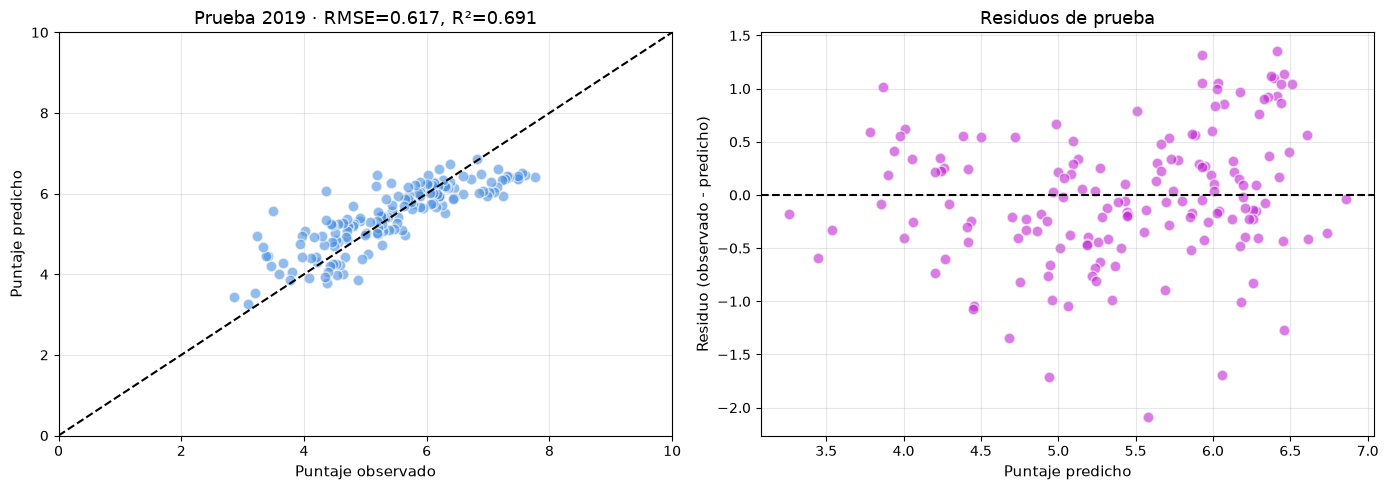

In [ ]:


# 2. Buscar los datos reales de 2019 en tu lista 'predictions'
pred_2019 = next(p for p in predictions if p["year"] == 2019)
y_true = pred_2019["y_true"]
y_pred = pred_2019["y_pred"]

# 3. Extraer RMSE y R2 directamente de df_res (para el título)
rmse_2019 = df_res[df_res['Validation Year'] == 2019]['RMSE'].values[0]
r2_2019 = df_res[df_res['Validation Year'] == 2019]['R2'].values[0]

# 4. Crear la figura con los dos gráficos
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# --- GRÁFICO 1: Observado vs Predicho (Izquierda) ---
ax1 = axes[0]
ax1.scatter(y_true, y_pred, color='#4A90E2', alpha=0.6, edgecolors='w', s=60)
# Línea diagonal perfecta (de 0 a 10)
ax1.plot([0, 10], [0, 10], color='black', linestyle='--', linewidth=1.5) 
ax1.set_title(f'Prueba 2019 · RMSE={rmse_2019:.3f}, R²={r2_2019:.3f}', fontsize=13)
ax1.set_xlabel('Puntaje observado', fontsize=11)
ax1.set_ylabel('Puntaje predicho', fontsize=11)
ax1.set_xlim(0, 10)
ax1.set_ylim(0, 10)
ax1.grid(True, alpha=0.3)

# --- GRÁFICO 2: Residuos (Derecha) ---
ax2 = axes[1]
residuos = y_true - y_pred
ax2.scatter(y_pred, residuos, color='#C026D3', alpha=0.6, edgecolors='w', s=60)
# Línea en cero (error cero)
ax2.axhline(0, color='black', linestyle='--', linewidth=1.5)
ax2.set_title('Residuos de prueba', fontsize=13)
ax2.set_xlabel('Puntaje predicho', fontsize=11)
ax2.set_ylabel('Residuo (observado - predicho)', fontsize=11)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

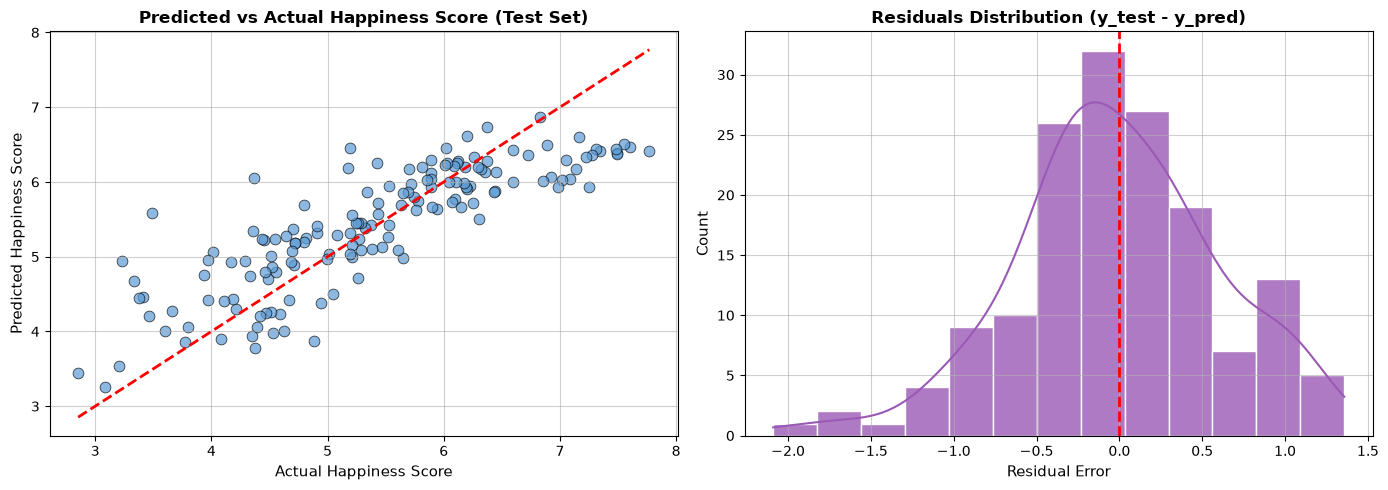

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Usamos las variables que ya tienes de la validación de 2019
residuos = y_true - y_pred

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# --- GRÁFICO 1: Predicho vs Actual ---
sns.scatterplot(x=y_true, y=y_pred, ax=axes[0], color='#5B9BD5', edgecolor='black', alpha=0.7, s=60)
# Línea roja punteada de ajuste perfecto
axes[0].plot([y_true.min(), y_true.max()], [y_true.min(), y_true.max()], color='red', linestyle='--', linewidth=2)
axes[0].set_title('Predicted vs Actual Happiness Score (Test Set)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Actual Happiness Score', fontsize=11)
axes[0].set_ylabel('Predicted Happiness Score', fontsize=11)
axes[0].grid(True, alpha=0.6)

# --- GRÁFICO 2: Distribución de Residuos (Histograma + KDE) ---
sns.histplot(residuos, kde=True, ax=axes[1], color='#9B59B6', edgecolor='white', alpha=0.8)
# Línea roja vertical en el cero
axes[1].axvline(0, color='red', linestyle='--', linewidth=2)
axes[1].set_title('Residuals Distribution (y_test - y_pred)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Residual Error', fontsize=11)
axes[1].set_ylabel('Count', fontsize=11)
axes[1].grid(True, alpha=0.6)

plt.tight_layout()
plt.show()

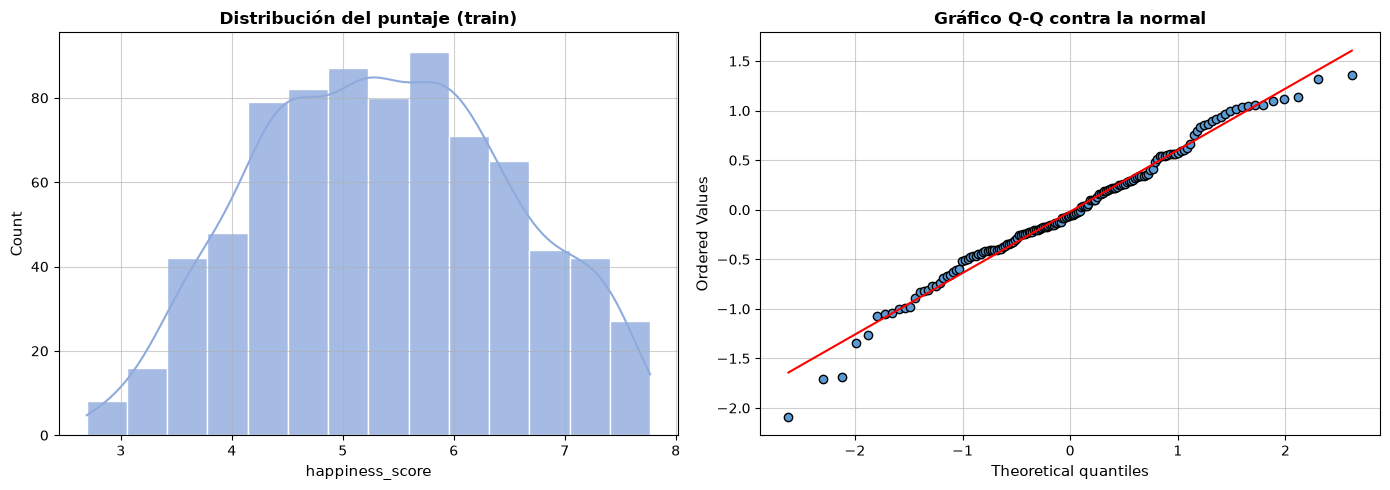

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# --- GRÁFICO 1: Distribución del puntaje ---
sns.histplot(happiness_df['happiness_score'], kde=True, ax=axes[0], color='#8FAADC', edgecolor='white', alpha=0.8)
axes[0].set_title('Distribución del puntaje (train)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('happiness_score', fontsize=11)
axes[0].set_ylabel('Count', fontsize=11)
axes[0].grid(True, alpha=0.6)

# --- GRÁFICO 2: Gráfico Q-Q contra la normal ---
# El gráfico Q-Q compara los cuantiles de nuestros residuos con una distribución normal teórica
stats.probplot(residuos, dist="norm", plot=axes[1])
axes[1].get_lines()[0].set_markerfacecolor('#5B9BD5') # Color de los puntos
axes[1].get_lines()[0].set_markeredgecolor('black')
axes[1].get_lines()[1].set_color('red') # Color de la línea de tendencia
axes[1].set_title('Gráfico Q-Q contra la normal', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Theoretical quantiles', fontsize=11)
axes[1].set_ylabel('Ordered Values', fontsize=11)
axes[1].grid(True, alpha=0.6)

plt.tight_layout()
plt.show()